# Plot results of parameter sweeps for Context Identification task
The purpose of this notebook is to plot some analyses of the results of a hyperparameter sweep performed on the `ContextIdentification` task. The parameters were:
1. Seed
2. Gamma
3. Task
4. Attention mechanism

## Imports

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

## Convert JSON to DataFrame

In [2]:
with open("../../data/context_identification_full_sweep.json", "r") as f:
    results = json.load(f)

In [3]:
rows = []
for label_mode, d1 in results.items():
    for attn_kind, d2 in d1.items():
        for gamma_str, d3 in d2.items():
            gamma = float(gamma_str)
            for seed_str, hist in d3.items():
                seed = int(seed_str)

                # history lists
                train_loss = np.array(hist["train_loss"], dtype=float)
                test_loss  = np.array(hist["test_loss"], dtype=float)
                train_acc  = np.array(hist["train_acc"], dtype=float)
                test_acc   = np.array(hist["test_acc"], dtype=float)

                rows.append({
                    "label_mode": label_mode,
                    "attn_kind": attn_kind,
                    "gamma": gamma,
                    "seed": seed,

                    "epochs": len(train_loss),

                    "final_train_loss": train_loss[-1],
                    "final_test_loss":  test_loss[-1],
                    "final_train_acc":  train_acc[-1],
                    "final_test_acc":   test_acc[-1],

                    # optional: best epoch metrics
                    "best_test_loss": float(test_loss.min()),
                    "best_test_acc":  float(test_acc.max()),
                })

In [4]:
df = pd.DataFrame(rows)
df.head()

,label_mode,attn_kind,gamma,seed,epochs,final_train_loss,final_test_loss,final_train_acc,final_test_acc,best_test_loss,best_test_acc
0,feature,linear,0.0,0,2500,0.021693,2.151865,0.994,0.900,0.859828,0.918
1,feature,linear,0.0,1,2500,0.013745,3.256781,0.998,0.886,1.064428,0.910
2,feature,linear,0.0,2,2500,0.108362,1.816224,0.980,0.860,0.808260,0.892
3,feature,linear,0.0,3,2500,0.018583,2.983617,0.998,0.874,1.060730,0.890
4,feature,linear,0.0,4,2500,0.037333,2.471541,0.994,0.894,0.579135,0.900


## Final loss plot

In [5]:
summary = (
    df.groupby(["label_mode", "attn_kind", "gamma"])["final_test_loss"]
      .agg(["mean", "std", "count"])
      .reset_index()
)
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

# Plot as lines over gamma, faceted by label_mode with style attn_kind
gams = np.sort(df["gamma"].unique())

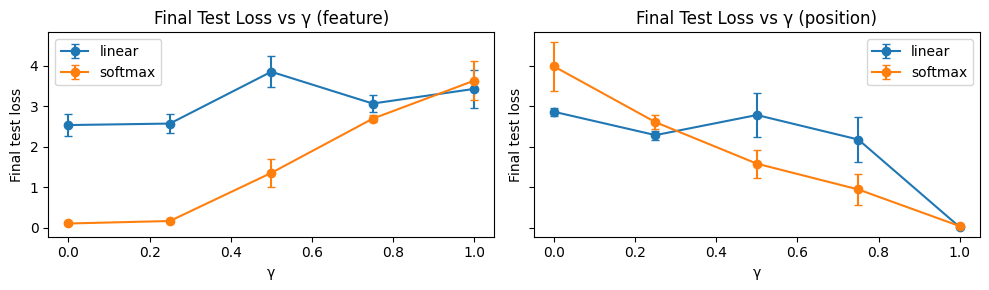

In [6]:
fig, axes = plt.subplots(1, df["label_mode"].nunique(), figsize=(10, 3), sharey=True)
if df["label_mode"].nunique() == 1:
    axes = [axes]

for ax, lm in zip(axes, sorted(df["label_mode"].unique())):
    sub = summary[summary["label_mode"] == lm]
    for ak in sorted(df["attn_kind"].unique()):
        s = sub[sub["attn_kind"] == ak].sort_values("gamma")
        ax.errorbar(s["gamma"], s["mean"], yerr=s["sem"], marker="o", capsize=3, label=ak)
    ax.set_title(f"Final Test Loss vs γ ({lm})")
    ax.set_xlabel("γ")
    ax.set_ylabel("Final test loss")
    ax.legend()

plt.tight_layout()
plt.show()

## Test accuracy heatmap

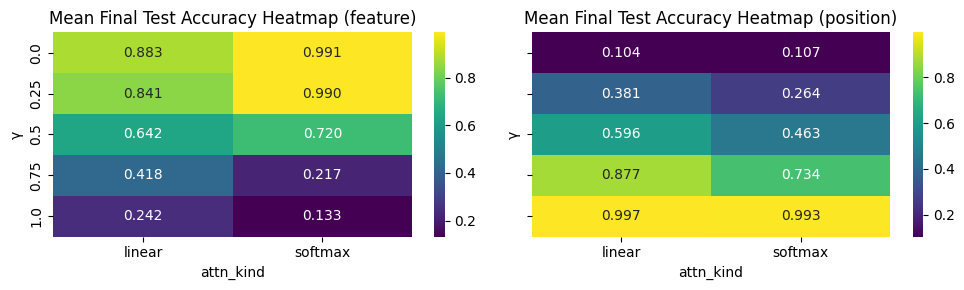

In [7]:
fig, axes = plt.subplots(1, df["label_mode"].nunique(), figsize=(10, 3), sharey=True)
if df["label_mode"].nunique() == 1:
    axes = [axes]

for ax, lm in zip(axes, sorted(df["label_mode"].unique())):
    pivot = (
        df[df["label_mode"] == lm]
        .groupby(["gamma", "attn_kind"])["final_test_acc"]
        .mean()
        .reset_index()
        .pivot(index="gamma", columns="attn_kind", values="final_test_acc")
        .sort_index()
    )

    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="viridis")
    ax.set_title(f"Mean Final Test Accuracy Heatmap ({lm})")
    ax.set_xlabel("attn_kind")
    ax.set_ylabel("γ")

plt.tight_layout()
plt.show()

## Train accuracy vs test accuracy

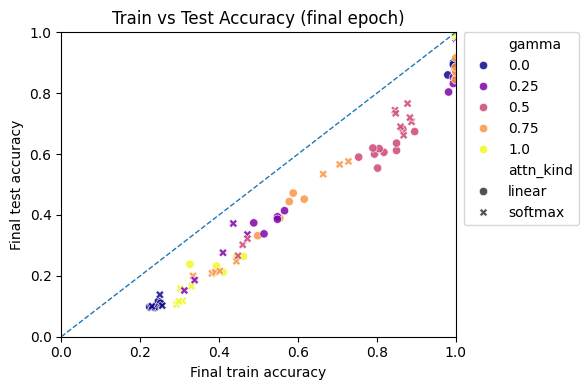

In [8]:
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df,
    x="final_train_acc",
    y="final_test_acc",
    hue="gamma",
    style="attn_kind",
    palette="plasma",
    alpha=0.85,
)
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)  # y=x line
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Final train accuracy")
plt.ylabel("Final test accuracy")
plt.title("Train vs Test Accuracy (final epoch)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.tight_layout()
plt.show()

## Accuracy distribution

In [9]:
# --- build long-form df for split violins ---
df_long = pd.concat(
    [
        df.rename(columns={"final_train_acc": "acc"}).assign(split="train")[
            ["label_mode", "attn_kind", "gamma", "seed", "split", "acc"]
        ],
        df.rename(columns={"final_test_acc": "acc"}).assign(split="test")[
            ["label_mode", "attn_kind", "gamma", "seed", "split", "acc"]
        ],
    ],
    ignore_index=True,
)

# Each condition gets a single x-axis entry
# (you can change formatting to taste)
df_long["condition"] = (
    df_long["attn_kind"].astype(str)
    + " | γ="
    + df_long["gamma"].map(lambda g: f"{float(g):.2f}")
)

# Consistent ordering: gamma increasing, then attn_kind
cond_order = (
    df_long[["gamma", "attn_kind", "condition"]]
    .drop_duplicates()
    .sort_values(["gamma", "attn_kind"])
    ["condition"]
    .tolist()
)

/var/folders/js/k9syvj8n4s16xsbs4fggvc000000gn/T/ipykernel_74138/1434743188.py:9: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(
/var/folders/js/k9syvj8n4s16xsbs4fggvc000000gn/T/ipykernel_74138/1434743188.py:9: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


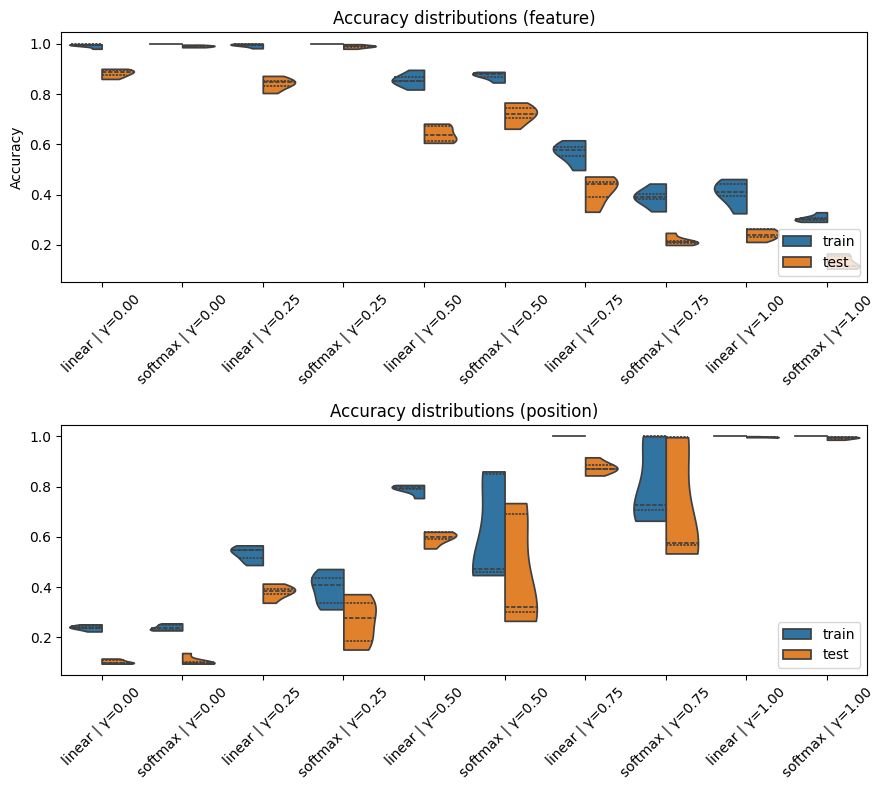

In [10]:
label_modes = sorted(df_long["label_mode"].unique())
fig, axes = plt.subplots(len(label_modes), 1, figsize=(4.5 * len(label_modes), 8), sharey=True)
if len(label_modes) == 1:
    axes = [axes]

for ax, lm in zip(axes, label_modes):
    sub = df_long[df_long["label_mode"] == lm].copy()

    sns.violinplot(
        data=sub,
        x="condition",
        y="acc",
        hue="split",          # must be exactly two levels for split=True
        order=cond_order,
        split=True,
        inner="quartile",
        cut=0,
        scale="width",
        ax=ax,
    )

    ax.set_title(f"Accuracy distributions ({lm})")
    ax.set_xlabel("")
    ax.set_ylabel("Accuracy" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=45)
    ax.legend_.set_title("")
    ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

## Testing accuracy curves

In [11]:
# results[label_mode][attn_kind][gamma][seed] -> history
ATTN_KIND = "softmax"
LABEL_MODES = ["feature", "position"]

# Choose shading: "sem" or "std"
shade = "sem"  # or "std"

# Grab available gammas from the file (strings -> floats)
gammas = sorted([float(g) for g in results[LABEL_MODES[0]][ATTN_KIND].keys()])
epochs = np.arange(len(next(iter(next(iter(results[LABEL_MODES[0]][ATTN_KIND].values())).values()))["test_acc"]))

<>:47: SyntaxWarning: invalid escape sequence '\g'
<>:47: SyntaxWarning: invalid escape sequence '\g'
/var/folders/js/k9syvj8n4s16xsbs4fggvc000000gn/T/ipykernel_74138/4261413839.py:47: SyntaxWarning: invalid escape sequence '\g'
  cbar.set_label("$\gamma$")


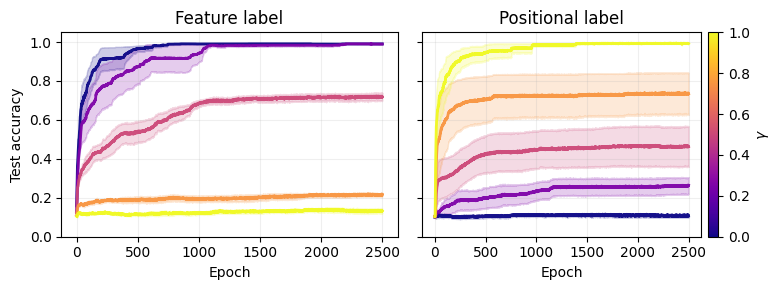

In [12]:
# Colormap setup
cmap = cm.plasma
norm = Normalize(vmin=min(gammas), vmax=max(gammas))

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True, sharey=True)

TITLES = {"feature": "Feature label", "position": "Positional label"}

for ax, lm in zip(axes, LABEL_MODES):
    for g in gammas:
        g_key = str(g)  # JSON keys are strings like "0.0"
        seed_dict = results[lm][ATTN_KIND][g_key]  # seed -> history

        # collect test_acc curves across seeds
        curves = []
        for seed_key, hist in seed_dict.items():
            curves.append(np.array(hist["test_acc"], dtype=float))
        curves = np.stack(curves, axis=0)  # (S, E)

        mean = curves.mean(axis=0)
        std = curves.std(axis=0, ddof=1) if curves.shape[0] > 1 else np.zeros_like(mean)

        if shade.lower() == "sem":
            err = std / np.sqrt(curves.shape[0]) if curves.shape[0] > 0 else std
            err_label = "SEM"
        elif shade.lower() == "std":
            err = std
            err_label = "STD"
        else:
            raise ValueError("shade must be 'sem' or 'std'")

        color = cmap(norm(g))
        ax.plot(epochs, mean, color=color, linewidth=2, alpha=0.95)
        ax.fill_between(epochs, mean - err, mean + err, color=color, alpha=0.20)

    ax.set_title(TITLES[lm])
    ax.set_xlabel("Epoch")
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Test accuracy")

# Shared colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes[1], location="right", pad=0.02,)
cbar.set_label("$\gamma$")

plt.tight_layout()
plt.savefig('../../results/context_identification/fixed_gamma/test_acc_dynamics_context_identification.png', dpi=300, bbox_inches='tight')
plt.show()

/var/folders/js/k9syvj8n4s16xsbs4fggvc000000gn/T/ipykernel_74138/321606074.py:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.83, 1])  # leave room for colorbar


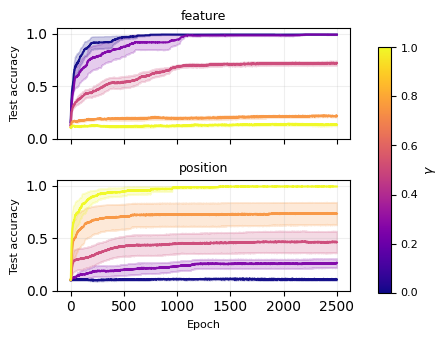

In [13]:
# Colormap setup
cmap = cm.plasma
norm = Normalize(vmin=min(gammas), vmax=max(gammas))

# Single-column: stack subplots vertically, narrower width
fig, axes = plt.subplots(2, 1, figsize=(4.5, 3.5), sharex=True, sharey=True)

for ax, lm in zip(axes, LABEL_MODES):
    for g in gammas:
        g_key = str(g)
        seed_dict = results[lm][ATTN_KIND][g_key]

        curves = []
        for seed_key, hist in seed_dict.items():
            curves.append(np.array(hist["test_acc"], dtype=float))
        curves = np.stack(curves, axis=0)  # (S, E)

        mean = curves.mean(axis=0)
        std = curves.std(axis=0, ddof=1) if curves.shape[0] > 1 else np.zeros_like(mean)

        if shade.lower() == "sem":
            err = std / np.sqrt(curves.shape[0]) if curves.shape[0] > 0 else std
            err_label = "SEM"
        elif shade.lower() == "std":
            err = std
            err_label = "STD"
        else:
            raise ValueError("shade must be 'sem' or 'std'")

        color = cmap(norm(g))
        ax.plot(epochs, mean, color=color, linewidth=1.5, alpha=0.95)
        ax.fill_between(epochs, mean - err, mean + err, color=color, alpha=0.20)

        ax.set_title(lm, fontsize=9)  # shorter title — suptitle carries the context
        ax.set_ylabel("Test accuracy", fontsize=8)
        ax.set_ylim(0.0, 1.05)
        ax.grid(alpha=0.2)

axes[-1].set_xlabel("Epoch", fontsize=8)

# Colorbar flush to the right of the whole figure
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.subplots_adjust(right=0.82)  # make room for colorbar
cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label("$\\gamma$", fontsize=9)
cbar.ax.tick_params(labelsize=8)

plt.tight_layout(rect=[0, 0, 0.83, 1])  # leave room for colorbar
plt.savefig(
    '../../results/context_identification/fixed_gamma/fixed_gamma_sweep_context_iden_ccn.png',
    dpi=300, bbox_inches='tight'
)
plt.show()